XGBoost Model: Risk_Level ~ AVG_NOISE_LVL
Data Split: 90% Train (6625 rows) | 10% Test (737 rows)
Train R²: 100.00% | Test Set Accuracy (R²): 100.00% | Test RMSE: 0.0002
Custom Prediction: When AVG_NOISE_LVL =  50  -->  Predicted Risk_Level = 1.0003
Custom Prediction: When AVG_NOISE_LVL =  85  -->  Predicted Risk_Level = 2.9998


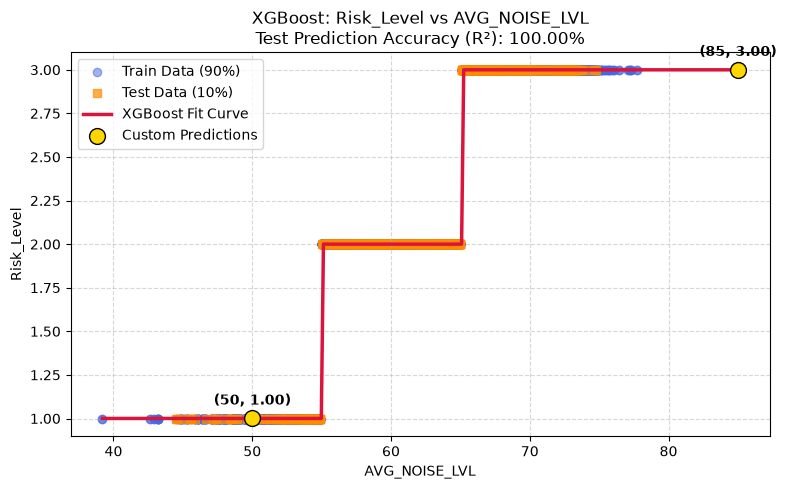

XGBoost Model: Duration_hours ~ AVG_NOISE_LVL
Data Split: 90% Train (6625 rows) | 10% Test (737 rows)
Train R²: 5.11% | Test Set Accuracy (R²): 2.13% | Test RMSE: 4.2915
Custom Prediction: When AVG_NOISE_LVL =  50  -->  Predicted Duration_hours = 9.7331
Custom Prediction: When AVG_NOISE_LVL =  85  -->  Predicted Duration_hours = 15.3164


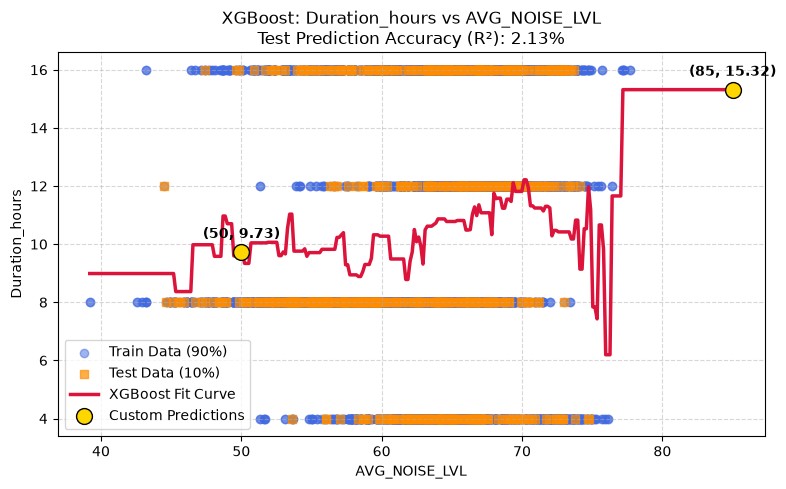

XGBoost Model: Risk_Level ~ Duration_hours
Data Split: 90% Train (6625 rows) | 10% Test (737 rows)
Train R²: 18.67% | Test Set Accuracy (R²): 18.63% | Test RMSE: 0.6078
Custom Prediction: When Duration_hours =   2  -->  Predicted Risk_Level = 2.4750
Custom Prediction: When Duration_hours =   8  -->  Predicted Risk_Level = 1.8825


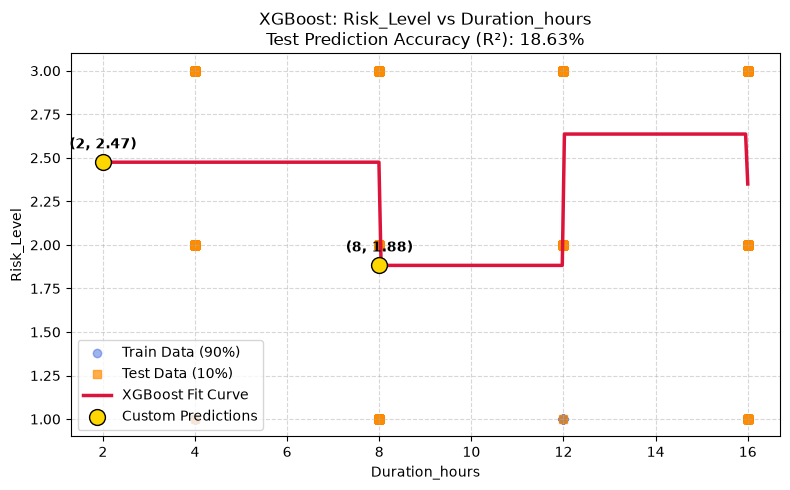

XGBoost Model: Duration_hours ~ LONGITUDE
Data Split: 90% Train (6625 rows) | 10% Test (737 rows)
Train R²: 5.48% | Test Set Accuracy (R²): 1.61% | Test RMSE: 4.3029
Custom Prediction: When LONGITUDE = 77.5  -->  Predicted Duration_hours = 10.9548
Custom Prediction: When LONGITUDE = 80.2  -->  Predicted Duration_hours = 10.9548


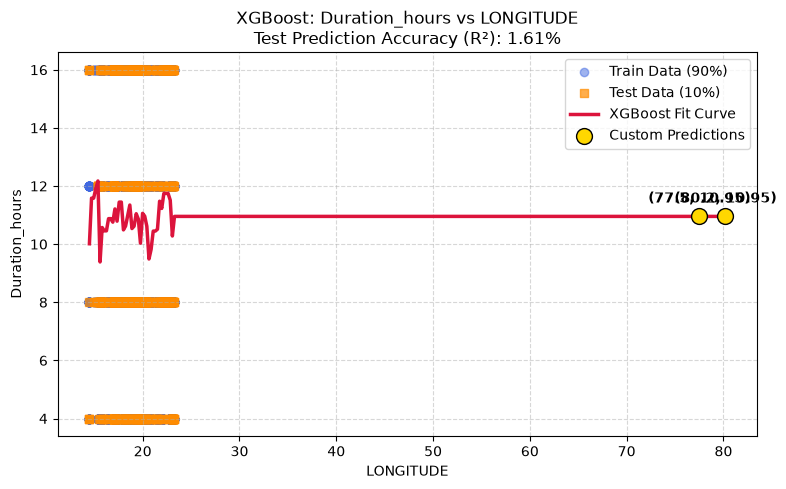

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from xgboost import XGBRegressor

# ==========================================================
# Load Excel File
# ==========================================================
file_path = r"Road_noise_measurements_filled (1).xlsx"
df = pd.read_excel(file_path, sheet_name="Road_noise_measurements")

# Fix column naming if lowercase/uppercase differences exist
df.columns = [c.strip() for c in df.columns]
if "Longitude" in df.columns and "LONGITUDE" not in df.columns:
    df.rename(columns={"Longitude": "LONGITUDE"}, inplace=True)

# ==========================================================
# Universal Risk_Level Parser
# ==========================================================
def parse_risk(val):
    if pd.isna(val):
        return np.nan
    s = str(val).strip().lower().replace(".0", "")
    mapping = {
        "1": 1.0, "low": 1.0, "l": 1.0,
        "2": 2.0, "medium": 2.0, "med": 2.0, "moderate": 2.0, "m": 2.0,
        "3": 3.0, "high": 3.0, "h": 3.0, "severe": 3.0
    }
    return mapping.get(s, np.nan)

df["Risk_Level"] = df["Risk_Level"].apply(parse_risk)

# Clean numeric feature columns
numeric_cols = ["AVG_NOISE_LVL", "Duration_hours", "LATITUDE", "LONGITUDE"]
for col in numeric_cols:
    if col in df.columns:
        df[col] = (
            df[col]
            .astype(str)
            .str.replace(",", ".", regex=False)
            .str.replace(r"[^\d.-]", "", regex=True)
        )
        df[col] = pd.to_numeric(df[col], errors="coerce")

# ==========================================================
# XGBoost Train-Test Split & Single Plot Function
# ==========================================================
def train_test_and_plot_xgboost(df, x_col, y_col, custom_inputs=[1, 100], test_size=0.20, random_state=42):
    # Prepare and clean pairwise data
    data = df[[x_col, y_col]].dropna().copy()

    if len(data) < 5:
        print(f"Not enough valid data points for {y_col} ~ {x_col}")
        return

    # Split dataset: 80% Train, 20% Test
    X = data[[x_col]]
    y = data[y_col]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )

    # Train XGBoost Regressor
    model = XGBRegressor(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.08,
        random_state=random_state
    )
    model.fit(X_train, y_train)

    # Predict on Train, Test, and Custom Inputs
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    
    custom_df = pd.DataFrame({x_col: custom_inputs})
    custom_preds = model.predict(custom_df)

    # Accuracy Metrics
    train_r2 = r2_score(y_train, y_train_pred) * 100
    test_r2 = r2_score(y_test, y_test_pred) * 100
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

    print("=" * 65)
    print(f"XGBoost Model: {y_col} ~ {x_col}")
    print(f"Data Split: {int((1-test_size)*100)}% Train ({len(X_train)} rows) | {int(test_size*100)}% Test ({len(X_test)} rows)")
    print(f"Train R²: {train_r2:.2f}% | Test Set Accuracy (R²): {test_r2:.2f}% | Test RMSE: {test_rmse:.4f}")
    for val, pred in zip(custom_inputs, custom_preds):
        print(f"Custom Prediction: When {x_col} = {val:>3}  -->  Predicted {y_col} = {pred:.4f}")
    print("=" * 65)

    # ======================================================
    # Visual Plot: Scatter Points & Non-Linear Regression Curve
    # ======================================================
    plt.figure(figsize=(8, 5))

    # Plot 80% Training Points
    plt.scatter(
        X_train[x_col], y_train,
        color="royalblue", alpha=0.5, label=f"Train Data ({int((1-test_size)*100)}%)"
    )

    # Plot 20% Test Points
    plt.scatter(
        X_test[x_col], y_test,
        color="darkorange", alpha=0.7, marker="s", label=f"Test Data ({int(test_size*100)}%)"
    )

    # Plot XGBoost Non-Linear Prediction Curve
    min_x = min(data[x_col].min(), min(custom_inputs))
    max_x = max(data[x_col].max(), max(custom_inputs))
    x_line = pd.DataFrame({x_col: np.linspace(min_x, max_x, 300)})
    y_line_pred = model.predict(x_line)

    plt.plot(
        x_line[x_col], y_line_pred,
        color="crimson", linewidth=2.5, label="XGBoost Fit Curve"
    )

    # Highlight Custom Predictions
    plt.scatter(
        custom_inputs, custom_preds,
        color="gold", edgecolors="black", s=130, zorder=5, label="Custom Predictions"
    )

    for val, pred in zip(custom_inputs, custom_preds):
        plt.annotate(
            f"({val}, {pred:.2f})",
            (val, pred),
            textcoords="offset points",
            xytext=(0, 10),
            ha="center",
            fontweight="bold"
        )

    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.title(f"XGBoost: {y_col} vs {x_col}\nTest Prediction Accuracy (R²): {test_r2:.2f}%")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend()
    plt.tight_layout()

    plt.savefig(f"XGBoost_{y_col}_vs_{x_col}_80_20_split.png", dpi=300)
    plt.show()

# ==========================================================
# Run Pairwise XGBoost Models
# ==========================================================
model_pairs = [
    ("AVG_NOISE_LVL", "Risk_Level", [50, 85]),
    ("AVG_NOISE_LVL", "Duration_hours", [50, 85]),
    ("Duration_hours", "Risk_Level", [2, 8]),
    ("LONGITUDE", "Duration_hours", [77.5, 80.2]),
]

for x_var, y_var, custom_vals in model_pairs:
    train_test_and_plot_xgboost(
        df=df,
        x_col=x_var,
        y_col=y_var,
        custom_inputs=custom_vals,
        test_size=0.10
    )